# Ranked pair strategy: 2026 analysis

Trade the validated pool in `data/pair_pool.csv`, ranked by 2025 Sharpe. Keep at most 15 active pairs. At every Close, restart the scan at rank 1 and select eligible entry signals for the following Open. Closed pairs may trade again; currently held pairs cannot be duplicated. All execution and accounting logic is in `pair_backtest.py`. No extra CSV is saved.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from pair_backtest import PairBacktestConfig, PairPoolBacktester
from risk import BetaAnalysis, RiskAnalysis

max_pairs = 15
long_amount = 1_000_000
start_date = "2026-01-01"
end_date = None  # Completed sessions; include today only after 17:00 New York time
allow_shared_tickers = False
borrow_fee_rate = 0.0
transaction_cost_rate = 0.0

config = PairBacktestConfig(
    max_pairs=max_pairs,
    long_amount=long_amount,
    start_date=start_date,
    end_date=end_date,
    allow_shared_tickers=allow_shared_tickers,
    borrow_fee_rate=borrow_fee_rate,
    transaction_cost_rate=transaction_cost_rate,
)
backtester = PairPoolBacktester.from_csv(Path("data/pair_pool.csv"), config)
print(f"Maximum active pairs: {max_pairs}")
print(f"strict_one_leg entry cap per pair side: ${config.leg_cap:,.2f}")
print(f"Fixed reference budget, including cash: ${2 * long_amount:,.2f}")
display(backtester.pairs[["rank", "pair_id", "validation_sharpe", "entry_z", "exit_z"]].head(15))

Maximum active pairs: 15
strict_one_leg entry cap per pair side: $66,666.67
Fixed reference budget, including cash: $2,000,000.00


,rank,pair_id,validation_sharpe,entry_z,exit_z
0,1,TSCO__DKS,3.168773,1.75,0.875
1,2,IOT__FICO,2.447722,0.75,0.375
2,3,IJH__MDY,2.437557,2.25,1.125
3,4,APO__AMP,2.376741,0.25,0.125
4,5,PSA__UDR,2.256158,2.75,1.375
5,6,CW__EMBJ,2.130160,1.50,0.750
6,7,IVE__IUSV,1.974488,1.25,0.625
7,8,VTI__ITOT,1.926911,0.50,0.250
8,9,VICI__GLPI,1.841946,0.75,0.375
9,10,SAP__CHKP,1.819871,1.00,0.500


## Trading rules

- Use `refit_alpha`, `refit_beta`, `refit_mu_e` and `refit_sigma_eq`, fitted through 2025 and frozen for 2026. The original fixed `mean_square` method and selected Z thresholds remain; no rolling z-score window or 2026 fitting is used.
- A Close entry signal fills at the next trading Open. The final 2025 Close can generate the first 2026 entry. January 1 need not be a trading day. High z shorts Y/longs X; low z reverses the direction.
- Entry sizing uses one common `strict_one_leg` scale, then rounds down to whole shares: each leg is at most `long_amount / max_pairs`. Actual long dollars can be lower after scaling/rounding. Limits apply at entry; fixed shares can drift above them as prices move.
- Close both legs when z reaches/crosses the exit threshold or the saved 12% trade stop triggers, using the following Open. Execute exits before new entries, then fill available slots by rank. Missing execution prices delay an exit or skip an entry. Restart each scan from the highest Sharpe. Skip currently held pairs. A closed pair becomes eligible again after its saved re-entry cooldown: with prevent_immediate_reentry=True, no new signal is generated for it on its execution-exit day. Tickers cannot overlap between simultaneous pairs by default.
- Leave unused capital in cash; fewer than 15 positions is allowed. `entry_count` counts all entries and `traded_pairs` counts distinct pairs; re-entry does not consume the pool permanently. Remaining holdings stay open at the final date, so final P&L includes realized and unrealized amounts.
- Fees, borrow, financing and distributions remain zero. Cumulative return is total P&L divided by the fixed USD 2 million reference budget. SPY is a price-return benchmark from the first session's Open. Tax deductions and after-tax returns are not calculated.

In [2]:
result = backtester.run()
daily_summary = result["daily_summary"]
daily_positions_long = result["daily_positions_long"]
daily_positions_short = result["daily_positions_short"]
events = result["events"]
closed_trades = result["closed_trades"]
open_positions = result["open_positions"]

print("Backtest dates:", daily_summary.index[0].date(), "to", daily_summary.index[-1].date())
opened = events.loc[events["event"].eq("open")]
print("Entry trades:", len(opened))
print("Distinct pairs traded:", opened["pair_id"].nunique())
print("Repeated pair entries:", len(opened) - opened["pair_id"].nunique())
print("Closed round trips:", len(closed_trades))
print("Remaining active pairs:", len(open_positions))
print("Eligible pool size:", len(backtester.pairs))
print("Maximum active pairs observed:", daily_summary["active_pairs"].max())
print("Missing tickers:", result["missing_tickers"])
print("Source events:", result["source_events"][:10])
display(daily_summary.tail().round(2))

Backtest dates: 2026-01-02 to 2026-10-22
Entry trades: 92
Distinct pairs traded: 21
Repeated pair entries: 71
Closed round trips: 77
Remaining active pairs: 15
Eligible pool size: 162
Maximum active pairs observed: 15
Missing tickers: []
Source events: []


,active_pairs,entry_count,traded_pairs,available_pairs,long_amount,short_amount,gross_amount,net_amount,cash,equity,...,realized_gain,realized_loss,cumulative_realized_gain,cumulative_realized_loss,cumulative_realized_pnl,unrealized_pnl,stale_price_legs,spy_close,spy_return,spy_cumulative_return
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-16,15,92,21,147,825309.07,-899344.12,1724653.19,-74035.05,2143329.29,2069294.24,...,0.0,0.0,375816.28,-299342.47,76473.81,-7179.57,0,763.25,-0.01,0.11
2026-10-19,15,92,21,147,821479.62,-895870.91,1717350.52,-74391.29,2143329.29,2068938.01,...,0.0,0.0,375816.28,-299342.47,76473.81,-7535.80,0,766.48,0.00,0.12
2026-10-20,15,92,21,147,829244.01,-904374.17,1733618.19,-75130.16,2143329.29,2068199.13,...,0.0,0.0,375816.28,-299342.47,76473.81,-8274.68,0,769.05,0.00,0.12
2026-10-21,15,92,21,147,832260.17,-908158.47,1740418.65,-75898.30,2143329.29,2067430.99,...,0.0,0.0,375816.28,-299342.47,76473.81,-9042.81,0,773.09,0.01,0.13
2026-10-22,15,92,21,147,842428.89,-910089.22,1752518.11,-67660.33,2143329.29,2075668.97,...,0.0,0.0,375816.28,-299342.47,76473.81,-804.84,0,763.96,-0.01,0.11


<Axes: title={'center': 'Active pairs'}, xlabel='Date'>

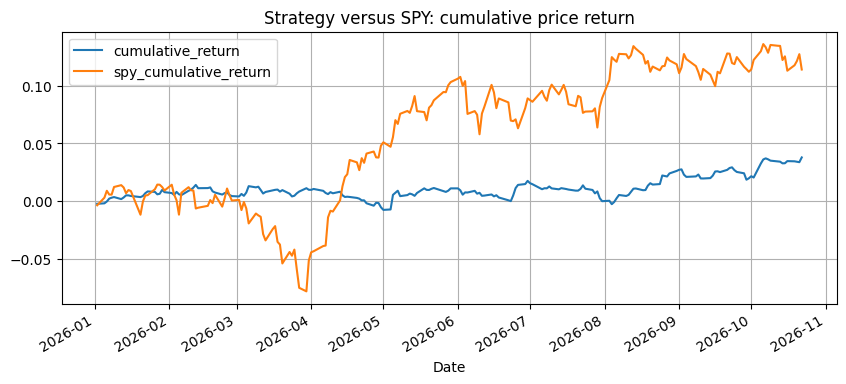

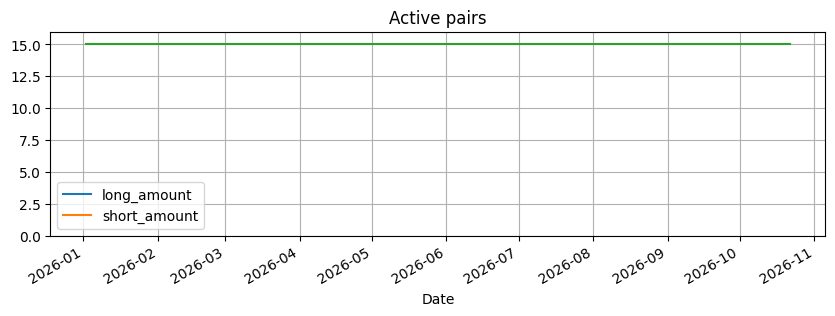

In [3]:
daily_summary[["cumulative_return", "spy_cumulative_return"]].plot(
    figsize=(10, 4), title="Strategy versus SPY: cumulative price return", grid=True,
)
daily_summary[["long_amount", "short_amount"]].plot(
    figsize=(10, 4), title="Daily long and signed short exposure (USD)", grid=True,
)
daily_summary["active_pairs"].plot(
    figsize=(10, 3), title="Active pairs", ylim=(0, max_pairs + 1), grid=True,
)

## Entries, exits and current holdings

Short shares and amounts are negative. `signal_date` is the prior Close that triggered the trade; `execution_date` is the actual Open fill. `rank` is the saved validation-Sharpe rank. Each close reports the two legs' realized P&L separately.

In [4]:
event_columns = [
    "execution_date", "signal_date", "event", "trade_id", "rank", "pair_id",
    "long_ticker", "short_ticker", "long_shares", "short_shares",
    "long_amount", "short_amount", "realized_pnl", "reason",
]
display(events[event_columns].head(30).round(2))
display(events[event_columns].tail(15).round(2))
holding_columns = [
    "entry_date", "trade_id", "rank", "pair_id", "long_ticker", "short_ticker",
    "long_shares", "short_shares", "long_amount", "short_amount", "unrealized_pnl", "z_score",
]
display(open_positions[holding_columns].round(4))

,execution_date,signal_date,event,trade_id,rank,pair_id,long_ticker,short_ticker,long_shares,short_shares,long_amount,short_amount,realized_pnl,reason
0,2026-01-02,2025-12-31,open,1,1,TSCO__DKS,TSCO,DKS,1334,-163,66659.98,-32433.74,0.00,z_entry
1,2026-01-02,2025-12-31,open,2,2,IOT__FICO,IOT,FICO,1857,-38,66666.30,-64259.14,0.00,z_entry
2,2026-01-02,2025-12-31,open,3,3,IJH__MDY,IJH,MDY,1001,-110,66346.28,-66646.80,0.00,z_entry
3,2026-01-02,2025-12-31,open,4,4,APO__AMP,AMP,APO,136,-361,66640.00,-52348.61,0.00,z_entry
4,2026-01-02,2025-12-31,open,5,5,PSA__UDR,PSA,UDR,257,-1254,66588.70,-45858.78,0.00,z_entry
5,2026-01-02,2025-12-31,open,6,7,IVE__IUSV,IUSV,IVE,648,-310,66569.04,-65868.80,0.00,z_entry
6,2026-01-02,2025-12-31,open,7,8,VTI__ITOT,ITOT,VTI,443,-197,66241.79,-66418.55,0.00,z_entry
7,2026-01-02,2025-12-31,open,8,9,VICI__GLPI,VICI,GLPI,2367,-1364,66654.72,-60793.48,0.00,z_entry
8,2026-01-02,2025-12-31,open,9,10,SAP__CHKP,CHKP,SAP,357,-189,66312.75,-45824.94,0.00,z_entry
9,2026-01-02,2025-12-31,open,10,11,FIX__STRL,STRL,FIX,172,-71,53221.96,-66626.40,0.00,z_entry


,execution_date,signal_date,event,trade_id,rank,pair_id,long_ticker,short_ticker,long_shares,short_shares,long_amount,short_amount,realized_pnl,reason
154,2026-09-21,2026-09-18,open,85,3,IJH__MDY,IJH,MDY,903,-99,66361.47,-66435.93,0.00,z_entry
155,2026-09-22,2026-09-21,close,64,7,IVE__IUSV,IVE,IUSV,289,-604,67539.30,-68300.32,-66.50,z_exit
156,2026-09-22,2026-09-21,close,85,3,IJH__MDY,IJH,MDY,903,-99,66496.92,-66503.25,68.13,z_exit
157,2026-09-22,2026-09-21,open,86,8,VTI__ITOT,ITOT,VTI,391,-174,66114.19,-66417.54,0.00,z_entry
158,2026-09-22,2026-09-21,open,87,17,XLU__VPU,XLU,VPU,1614,-375,65512.26,-66483.75,0.00,z_entry
159,2026-09-24,2026-09-23,close,87,17,XLU__VPU,XLU,VPU,1614,-375,64366.32,-64777.50,560.31,z_exit
160,2026-09-24,2026-09-23,open,88,3,IJH__MDY,MDY,IJH,100,-913,66401.00,-66429.88,0.00,z_entry
161,2026-09-29,2026-09-28,close,86,8,VTI__ITOT,ITOT,VTI,391,-174,65410.39,-65545.80,167.94,z_exit
162,2026-09-29,2026-09-28,open,89,7,IVE__IUSV,IUSV,IVE,598,-286,66449.76,-65751.40,0.00,z_entry
163,2026-09-30,2026-09-29,close,79,2,IOT__FICO,FICO,IOT,35,-1704,21070.70,-64837.20,-13142.02,stop


,entry_date,trade_id,rank,pair_id,long_ticker,short_ticker,long_shares,short_shares,long_amount,short_amount,unrealized_pnl,z_score
3036,2026-05-29,65,1,TSCO__DKS,TSCO,DKS,2157,-264,74912.6090,-39277.9197,28433.5508,-25.4184
3043,2026-10-05,91,2,IOT__FICO,FICO,IOT,32,-1587,26344.6406,-69478.8581,2344.4232,23.8564
3041,2026-09-24,88,3,IJH__MDY,MDY,IJH,100,-913,66400.0000,-66466.4028,-37.5218,15.0950
3037,2026-06-29,73,4,APO__AMP,APO,AMP,389,-146,44668.8707,-72537.1780,-7957.9079,-16.3578
3034,2026-04-07,50,5,PSA__UDR,UDR,PSA,1161,-238,42004.9804,-73572.9412,-5303.6520,10.1221
3040,2026-09-16,81,6,CW__EMBJ,CW,EMBJ,117,-841,55490.7599,-58205.6092,-6125.4691,-11.8437
3044,2026-10-06,92,8,VTI__ITOT,VTI,ITOT,174,-391,65232.5989,-65062.3976,72.6716,0.2164
3030,2026-01-02,8,9,VICI__GLPI,VICI,GLPI,2367,-1364,56855.3411,-54587.2806,-3593.1796,-7.7732
3039,2026-08-25,80,10,SAP__CHKP,CHKP,SAP,512,-271,77813.7578,-65199.8890,4505.2766,17.3909
3038,2026-08-05,77,11,FIX__STRL,STRL,FIX,90,-37,33554.6988,-47336.6898,3042.0961,32.4392


In [5]:
long_tail = daily_positions_long.tail()
short_tail = daily_positions_short.tail()
display(long_tail.loc[:, long_tail.ne(0).any()].round(2))
display(short_tail.loc[:, short_tail.ne(0).any()].round(2))

ticker,TSCO,FICO,MDY,APO,UDR,CW,VTI,VICI,CHKP,STRL,KEY,WEC,BLK,SPGI,EPD
Date,,,,,,,,,,,,,,,
2026-10-16,71526.12,24678.08,65987.0,43093.42,39775.86,58771.44,65088.18,55861.20,70589.44,38192.4,42758.61,64138.9,58987.76,58001.40,67859.26
2026-10-19,70771.17,24994.24,66040.0,43159.55,39288.24,58161.87,65343.96,54677.70,71132.16,38113.2,42608.88,63130.0,58479.20,57757.05,67822.40
2026-10-20,70986.87,25591.36,66692.0,43264.58,39950.01,57944.25,65613.66,55316.79,72115.20,37102.5,44512.59,64162.5,58691.36,59146.20,68154.14
2026-10-21,70512.33,25446.72,66942.0,43447.41,40681.44,57820.23,65972.10,54796.05,73436.16,37166.4,44983.17,64015.0,59779.20,59826.60,67435.37
2026-10-22,74912.61,26344.64,66400.0,44668.87,42004.98,55490.76,65232.60,56855.34,77813.76,33554.7,45368.19,66168.5,59139.08,61168.50,67306.36


ticker,DKS,IOT,IJH,AMP,PSA,EMBJ,ITOT,GLPI,SAP,FIX,USB,AEE,SEIC,MCO,TRGP
Date,,,,,,,,,,,,,,,
2026-10-16,-38108.40,-62797.59,-66055.55,-73116.80,-70997.78,-60837.94,-64937.28,-53577.92,-60782.59,-53245.59,-73412.5,-63648.0,-74959.20,-51902.49,-30964.50
2026-10-19,-37955.28,-63956.10,-66082.94,-70139.86,-70374.22,-61603.25,-65187.52,-52950.48,-61254.13,-54170.59,-72312.5,-62406.0,-75239.22,-51494.82,-30744.00
2026-10-20,-37773.12,-67272.93,-66731.17,-71199.82,-71818.88,-60863.17,-65457.31,-53386.96,-62053.58,-51692.33,-73862.5,-63738.0,-76933.70,-50862.45,-30728.25
2026-10-21,-37480.08,-68621.88,-67005.07,-71614.46,-70997.78,-61308.90,-65840.49,-52309.40,-63069.83,-51846.99,-73812.5,-63888.0,-77852.74,-51472.35,-31038.00
2026-10-22,-39277.92,-69478.86,-66466.40,-72537.18,-73572.94,-58205.61,-65062.40,-54587.28,-65199.89,-47336.69,-75025.0,-65364.0,-75031.00,-52542.35,-30401.70


## P&L and risk

Realized losses sum the losing **legs**, including a losing leg in an overall profitable pair. At every date, cumulative P&L equals cumulative realized P&L plus remaining unrealized P&L. VaR/CVaR below use dollar daily P&L. Market beta uses daily strategy/SPY returns, excluding the first Open-to-Close day.

In [6]:
pnl_columns = [
    "cumulative_realized_loss", "cumulative_realized_gain",
    "cumulative_realized_pnl", "unrealized_pnl", "cumulative_pnl",
]
display(daily_summary.iloc[-1][pnl_columns].to_frame("USD").round(2))
print(f"Strategy return on fixed budget: {daily_summary['cumulative_return'].iloc[-1]:.2%}")
print(f"SPY price return: {daily_summary['spy_cumulative_return'].iloc[-1]:.2%}")

risk_analysis = RiskAnalysis(daily_summary["daily_pnl"].iloc[1:], confidence=0.95)
display(risk_analysis.summary().round(2))

,USD
cumulative_realized_loss,-299342.47
cumulative_realized_gain,375816.28
cumulative_realized_pnl,76473.81
unrealized_pnl,-804.84
cumulative_pnl,75668.97


Strategy return on fixed budget: 3.78%
SPY price return: 11.41%


,VaR,CVaR
Method,,
Historical,6144.41,8474.14
Parametric (normal),7610.88,9645.54


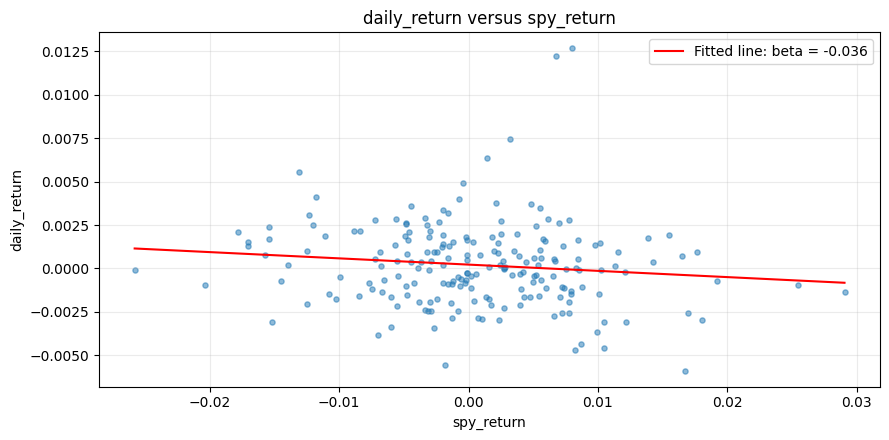

Alpha: 0.000220; beta: -0.0360


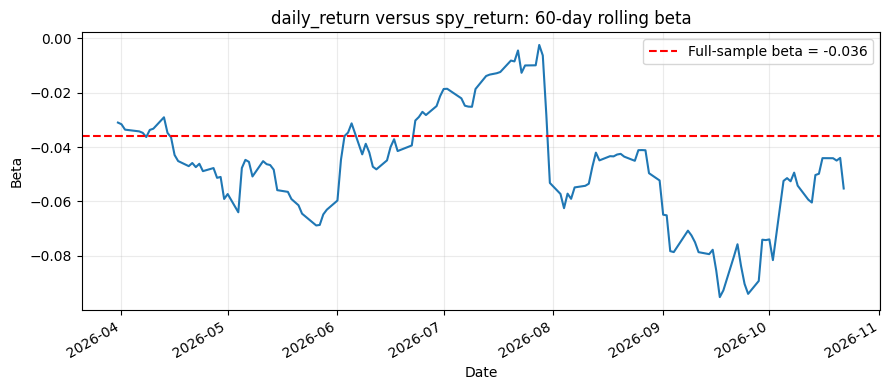

Latest rolling beta: -0.0552


In [7]:
beta_analysis = BetaAnalysis(
    x=daily_summary["spy_return"].iloc[1:],
    y=daily_summary["daily_return"].iloc[1:],
)
beta_analysis.plot_regression()
rolling_beta = beta_analysis.plot_rolling_beta(window=60)

## Where P&L comes from

Pair contributions include every closed round trip plus any remaining open-position P&L. `holding_days` measures the age of the current holding in calendar days. These diagnostics explain the observed test result; they do not retune the model using 2026.

In [8]:
print("Lowest pair P&L contributions")
display(result["pair_performance"].head(8).round(2))
print("Exit reasons")
display(closed_trades["reason"].value_counts().to_frame("trades"))
print("Longest current holdings")
display(open_positions.sort_values("holding_days", ascending=False)[
    ["pair_id", "entry_date", "holding_days", "unrealized_pnl", "z_score"]
].head(5).round(2))

Lowest pair P&L contributions


,closed_trades,realized_pnl,unrealized_pnl,holding_days,total_pnl,rank,validation_sharpe
pair_id,,,,,,,
USB__KEY,0.0,0.00,-7121.88,293.0,-7121.88,12,1.73
IOT__FICO,6.0,-6611.26,2344.42,17.0,-4266.84,2,2.45
VICI__GLPI,0.0,0.00,-3593.18,293.0,-3593.18,9,1.84
SPGI__MCO,0.0,0.00,-3479.36,293.0,-3479.36,16,1.55
SAP__CHKP,3.0,-4701.32,4505.28,58.0,-196.05,10,1.82
XLF__VFH,1.0,-133.41,0.00,0.0,-133.41,22,1.44
IVE__IUSV,7.0,73.34,0.00,0.0,73.34,7,1.97
IJH__MDY,9.0,320.19,-37.52,28.0,282.67,3,2.44


Exit reasons


,trades
reason,
z_exit,69
stop,8


Longest current holdings


,pair_id,entry_date,holding_days,unrealized_pnl,z_score
3032,SPGI__MCO,2026-01-02,293,-3479.36,-15.10
3031,USB__KEY,2026-01-02,293,-7121.88,19.07
3030,VICI__GLPI,2026-01-02,293,-3593.18,-7.77
3033,WEC__AEE,2026-02-13,251,-269.30,-10.75
3034,PSA__UDR,2026-04-07,198,-5303.65,10.12
